# 02 - Set-top box maintenance timing and an off-peak schedule

**Business question.** Channel maintenance (encoder firmware, stream configuration pushes, EPG
refreshes, plus unplanned incidents) interrupts viewers tuned to the affected channel. When does
maintenance happen, how many viewers does it hit, and how much disruption would moving deferrable
work to an overnight window avoid?

**Approach.**
1. Profile maintenance timing across the channel lineup against the viewing curve.
2. Interval-join every maintenance window to the sessions it overlaps (non-zap LIVE and StartOver
   sessions on that channel; catch-up, cloud DVR and VOD are served from storage and unaffected).
3. Measure reach (devices affected), disrupted sessions and disrupted viewer-minutes.
4. Simulate a schedule that moves deferrable peak-hour work to the lowest-viewing overnight slot
   for each channel, with a crew capacity limit, and replay the same sessions against it.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../src").resolve()))
import sessionize as sz

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RAW, PROC, FIG = Path("../data/raw"), Path("../data/processed"), Path("../reports/figures")
PEAK_HOURS = range(18, 22)          # 18:00-21:59
AFFECTED_MODES = ["LIVE", "STARTOVER"]

sessions, _ = sz.build_sessions(RAW / "stb_events.csv.gz", cache=PROC / "fact_session.csv.gz")
maint = pd.read_csv(RAW / "maintenance_events.csv", parse_dates=["start_time"])
maint["end_time"] = maint.start_time + pd.to_timedelta(maint.duration_min, unit="m")
maint["is_peak"] = maint.start_time.dt.hour.isin(PEAK_HOURS)
channels = pd.read_csv(RAW / "channels.csv")
print(f"sessions: {len(sessions):,} | maintenance events: {len(maint)} on {maint.channel_id.nunique()} of {len(channels)} channels")

sessions: 1,198,334 | maintenance events: 494 on 123 of 126 channels


## 1. When does maintenance happen?

In [2]:
timing = pd.DataFrame({
    "events": maint.groupby("is_planned").size(),
    "peak_share": maint.groupby("is_planned").is_peak.mean(),
}).rename(index={True: "planned", False: "unplanned"})
timing.loc["all"] = [len(maint), maint.is_peak.mean()]
display(timing.round(3))
display(maint.groupby("maintenance_type").agg(events=("maintenance_id", "size"), peak_share=("is_peak", "mean"),
                                              deferrable=("deferrable", "mean"), median_minutes=("duration_min", "median")).round(3))

,events,peak_share
is_planned,,
unplanned,205.0,0.605
planned,289.0,0.716
all,494.0,0.670


,events,peak_share,deferrable,median_minutes
maintenance_type,,,,
EPG metadata refresh,92,0.696,0.707,22.0
Encoder firmware update,106,0.679,0.783,20.0
Encoder restart (incident),105,0.657,0.000,35.0
Origin failover (incident),100,0.550,0.000,39.5
Stream config push,91,0.780,0.868,21.0


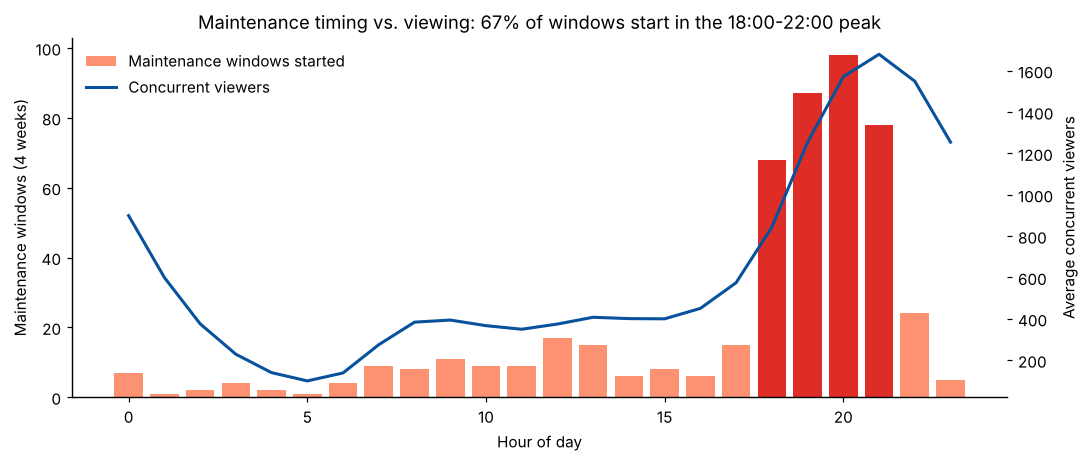

In [3]:
viewing = sessions[~sessions.is_zap]
hourly_view = pd.read_csv(PROC / "agg_hourly_channel_viewing.csv.gz", dtype={"channel_id": "string"})
n_days = hourly_view.view_date.nunique()
view_by_hour = hourly_view.groupby("view_hour").viewer_minutes.sum() / n_days / 60

fig, ax1 = plt.subplots(figsize=(10, 4.3))
cnt = maint.start_time.dt.hour.value_counts().reindex(range(24), fill_value=0)
ax1.bar(cnt.index, cnt.values, color=["#de2d26" if h in PEAK_HOURS else "#fc9272" for h in cnt.index],
        label="Maintenance windows started")
ax1.set_xlabel("Hour of day"); ax1.set_ylabel("Maintenance windows (4 weeks)")
ax2 = ax1.twinx()
ax2.plot(view_by_hour.index, view_by_hour.values, color="#08519c", lw=2, label="Concurrent viewers")
ax2.set_ylabel("Average concurrent viewers"); ax2.spines["top"].set_visible(False)
ax1.set_title(f"Maintenance timing vs. viewing: {maint.is_peak.mean():.0%} of windows start in the 18:00-22:00 peak")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "02_maintenance_vs_viewing.png", bbox_inches="tight"); plt.show()

## 2. Who is affected? Interval join of windows and sessions

For each window, find the sessions on that channel where `session_start < window_end` and
`session_end > window_start`. Disrupted minutes are the overlap length. (Snowflake version:
`MARTS.FACT_MAINTENANCE_IMPACT` in `sql/03_marts.sql`.)

In [4]:
exposed = viewing[viewing.playback_mode.isin(AFFECTED_MODES)]
by_channel = {c: g[["session_id", "device_id", "session_start", "session_end"]] for c, g in exposed.groupby("channel_id")}

def impact(windows: pd.DataFrame) -> pd.DataFrame:
    """Sessions overlapping each maintenance window, with overlap minutes."""
    out = []
    for w in windows.itertuples():
        g = by_channel.get(w.channel_id)
        if g is None:
            continue
        hit = g[(g.session_start < w.end_time) & (g.session_end > w.start_time)]
        if hit.empty:
            continue
        ov = (np.minimum(hit.session_end, w.end_time) - np.maximum(hit.session_start, w.start_time))
        out.append(pd.DataFrame({"maintenance_id": w.maintenance_id, "session_id": hit.session_id.values,
                                 "device_id": hit.device_id.values,
                                 "disrupted_minutes": ov.dt.total_seconds().values / 60}))
    return pd.concat(out, ignore_index=True).merge(
        windows[["maintenance_id", "start_time", "is_peak", "deferrable", "is_planned"]], on="maintenance_id")

hits = impact(maint)
per_event = (hits.groupby("maintenance_id").agg(devices=("device_id", "nunique"), minutes=("disrupted_minutes", "sum"))
             .reindex(maint.maintenance_id, fill_value=0).join(maint.set_index("maintenance_id")[["is_peak"]]))
display(per_event.groupby("is_peak")[["devices", "minutes"]].mean().round(1)
        .rename(index={True: "peak window", False: "off-peak window"})
        .rename(columns={"devices": "avg devices hit per window", "minutes": "avg disrupted viewer-minutes"}))

,avg devices hit per window,avg disrupted viewer-minutes
is_peak,,
off-peak window,14.9,250.5
peak window,25.8,369.6


In [5]:
week = lambda ts: (ts.dt.normalize() - pd.to_timedelta(ts.dt.dayofweek, unit="D"))
active_week = sessions.assign(wk=week(sessions.session_start)).groupby("wk").device_id.nunique()

def reach(h: pd.DataFrame) -> pd.DataFrame:
    w = h.assign(wk=week(h.start_time))
    r = pd.DataFrame({"active_devices": active_week,
                      "affected_devices": w.groupby("wk").device_id.nunique(),
                      "affected_by_peak_windows": w[w.is_peak].groupby("wk").device_id.nunique()}).fillna(0)
    r = r[r.index < pd.Timestamp("2025-03-31")]  # four full weeks
    r["affected_share"] = r.affected_devices / r.active_devices
    r["affected_share_peak"] = r.affected_by_peak_windows / r.active_devices
    return r

weekly_reach = reach(hits)
display(weekly_reach.round(3))
base = pd.Series({
    "maintenance windows": len(maint),
    "channels with maintenance": maint.channel_id.nunique(),
    "share of windows starting 18:00-22:00": maint.is_peak.mean(),
    "avg weekly share of active devices affected": weekly_reach.affected_share.mean(),
    "  of which by peak windows": weekly_reach.affected_share_peak.mean(),
    "disrupted sessions": len(hits),
    "share of disrupted sessions from peak windows": hits.is_peak.mean(),
    "disrupted viewer-minutes": hits.disrupted_minutes.sum(),
    "share of disrupted minutes from peak windows": hits.loc[hits.is_peak, "disrupted_minutes"].sum() / hits.disrupted_minutes.sum(),
    "devices affected at least once in 4 weeks (share)": hits.device_id.nunique() / sessions.device_id.nunique(),
})
base.round(3).rename("current schedule").to_frame()

,active_devices,affected_devices,affected_by_peak_windows,affected_share,affected_share_peak
wk,,,,,
2025-03-03,9745,2653.0,2137.0,0.272,0.219
2025-03-10,9768,2281.0,1748.0,0.234,0.179
2025-03-17,9776,2137.0,1951.0,0.219,0.200
2025-03-24,9733,1951.0,1455.0,0.200,0.149


,current schedule
maintenance windows,494.000
channels with maintenance,123.000
share of windows starting 18:00-22:00,0.670
avg weekly share of active devices affected,0.231
of which by peak windows,0.187
disrupted sessions,11326.000
share of disrupted sessions from peak windows,0.775
disrupted viewer-minutes,163160.500
share of disrupted minutes from peak windows,0.750
devices affected at least once in 4 weeks (share),0.601


## 3. Proposed schedule: deferrable work moves overnight

Rules for the simulation:
* Only windows flagged `deferrable` (planned work with no hard vendor or security deadline) and
  starting in the 18:00-22:00 peak are moved. Unplanned incidents and non-deferrable work stay put.
* Each moved window goes to the same night's 01:00-05:00 window, in the hour with the lowest
  historical viewing for that channel.
* Crew capacity: at most `CAPACITY` windows may start in the same overnight hour; overflow takes
  the next-best hour, and if the night is full the window stays where it was.
* Viewing behaviour is held fixed: the same observed sessions are replayed against the new
  schedule.

In [6]:
NIGHT_HOURS = [1, 2, 3, 4]
ch_hour = (hourly_view[hourly_view.playback_mode.isin(AFFECTED_MODES)]
           .groupby(["channel_id", "view_hour"]).viewer_minutes.sum().unstack(fill_value=0)
           .reindex(columns=range(24), fill_value=0))

def reschedule(m: pd.DataFrame, capacity: int, movable_mask: pd.Series) -> pd.DataFrame:
    m = m.copy()
    m["moved"] = False
    used = {}
    for idx in m[movable_mask].sort_values("start_time").index:
        w = m.loc[idx]
        night = w.start_time.normalize() + pd.Timedelta(days=1)
        prefs = ch_hour.loc[w.channel_id, NIGHT_HOURS].sort_values().index if w.channel_id in ch_hour.index else NIGHT_HOURS
        for h in prefs:
            key = (night, h)
            if used.get(key, 0) < capacity:
                used[key] = used.get(key, 0) + 1
                new_start = night + pd.Timedelta(hours=int(h), minutes=int(w.start_time.minute))
                m.loc[idx, ["start_time", "end_time"]] = [new_start, new_start + pd.Timedelta(minutes=int(w.duration_min))]
                m.loc[idx, "moved"] = True
                break
    m["is_peak_new"] = m.start_time.dt.hour.isin(PEAK_HOURS)
    return m

CAPACITY = 3
movable = maint.deferrable & maint.is_peak
proposed = reschedule(maint, CAPACITY, movable)
print(f"deferrable peak windows: {movable.sum()} | moved: {proposed.moved.sum()} | "
      f"peak share of windows after: {proposed.is_peak_new.mean():.1%}")

deferrable peak windows: 168 | moved: 168 | peak share of windows after: 33.0%


In [7]:
# replay: disruption is attributed to the hour the window runs in after rescheduling
hits_new = impact(proposed.drop(columns="is_peak").rename(columns={"is_peak_new": "is_peak"}))

def summarize(h, m):
    r = reach(h)
    peak_min = h.loc[h.is_peak, "disrupted_minutes"].sum()
    return pd.Series({
        "share of windows starting 18:00-22:00": m.is_peak.mean() if "is_peak_new" not in m else m.is_peak_new.mean(),
        "avg weekly share of active devices affected": r.affected_share.mean(),
        "disrupted sessions": len(h),
        "peak-hour disrupted sessions": int(h.is_peak.sum()),
        "disrupted viewer-minutes": h.disrupted_minutes.sum(),
        "peak-hour disrupted viewer-minutes": peak_min,
    })

compare = pd.DataFrame({"current": summarize(hits, maint), "proposed": summarize(hits_new, proposed)})
compare["change"] = compare.proposed / compare.current - 1
compare.round(3)

,current,proposed,change
share of windows starting 18:00-22:00,0.670,0.330,-0.508
avg weekly share of active devices affected,0.231,0.176,-0.237
disrupted sessions,11326.000,8187.000,-0.277
peak-hour disrupted sessions,8778.000,5299.000,-0.396
disrupted viewer-minutes,163160.500,126848.983,-0.223
peak-hour disrupted viewer-minutes,122328.683,81334.000,-0.335


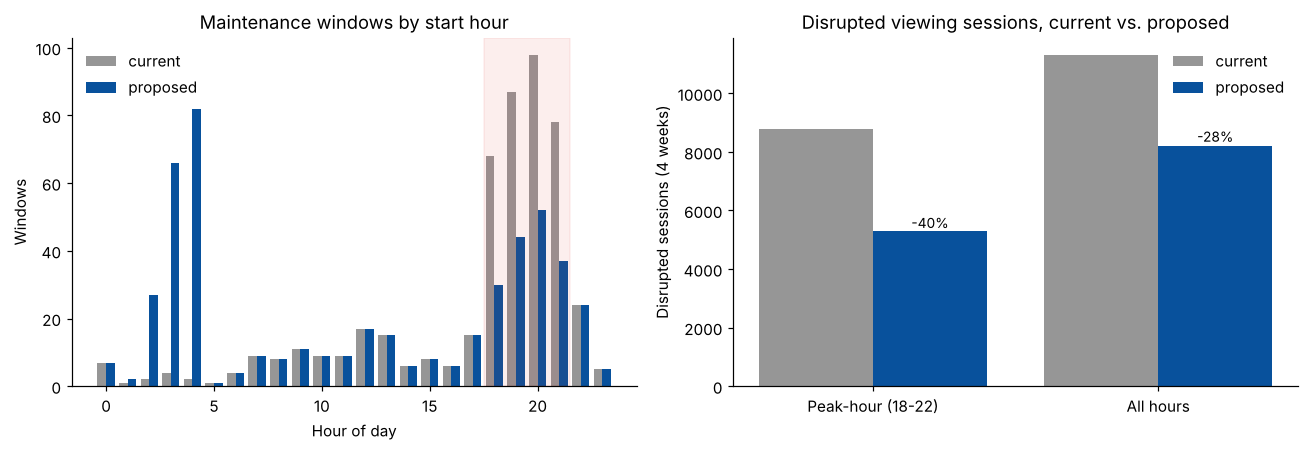

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
cnt_new = proposed.start_time.dt.hour.value_counts().reindex(range(24), fill_value=0)
axes[0].bar(np.arange(24) - 0.2, cnt.values, width=0.4, color="#969696", label="current")
axes[0].bar(np.arange(24) + 0.2, cnt_new.values, width=0.4, color="#08519c", label="proposed")
axes[0].axvspan(17.5, 21.5, color="#de2d26", alpha=0.08)
axes[0].set_title("Maintenance windows by start hour"); axes[0].set_xlabel("Hour of day"); axes[0].set_ylabel("Windows")
axes[0].legend(frameon=False)
metrics = ["peak-hour disrupted sessions", "disrupted sessions"]
x = np.arange(len(metrics))
axes[1].bar(x - 0.2, compare.loc[metrics, "current"], width=0.4, color="#969696", label="current")
axes[1].bar(x + 0.2, compare.loc[metrics, "proposed"], width=0.4, color="#08519c", label="proposed")
for i, m_ in enumerate(metrics):
    axes[1].text(i + 0.2, compare.loc[m_, "proposed"] * 1.02, f"{compare.loc[m_, 'change']:+.0%}", ha="center", fontsize=9)
axes[1].set_xticks(x, ["Peak-hour (18-22)", "All hours"]); axes[1].set_ylabel("Disrupted sessions (4 weeks)")
axes[1].set_title("Disrupted viewing sessions, current vs. proposed"); axes[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "02_schedule_simulation.png", bbox_inches="tight"); plt.show()

## 4. Sensitivity

How much depends on crew capacity and on which work can be moved?

In [9]:
rows = []
for label, mask in [("deferrable planned only", maint.deferrable & maint.is_peak),
                    ("all planned work", maint.is_planned & maint.is_peak)]:
    for cap in [1, 2, 3, 5]:
        p = reschedule(maint, cap, mask)
        h = impact(p.drop(columns="is_peak").rename(columns={"is_peak_new": "is_peak"}))
        s = summarize(h, p)
        rows.append({"movable set": label, "capacity per hour": cap, "windows moved": int(p.moved.sum()),
                     "peak-hour disrupted sessions change": s["peak-hour disrupted sessions"] / compare.loc["peak-hour disrupted sessions", "current"] - 1,
                     "all disrupted sessions change": s["disrupted sessions"] / compare.loc["disrupted sessions", "current"] - 1,
                     "weekly affected share": s["avg weekly share of active devices affected"]})
sens = pd.DataFrame(rows)
sens.round(3)

,movable set,capacity per hour,windows moved,peak-hour disrupted sessions change,all disrupted sessions change,weekly affected share
0,deferrable planned only,1,106,-0.205,-0.125,0.207
1,deferrable planned only,2,162,-0.386,-0.257,0.180
2,deferrable planned only,3,168,-0.396,-0.277,0.176
3,deferrable planned only,5,168,-0.396,-0.284,0.175
4,all planned work,1,112,-0.172,-0.105,0.211
5,all planned work,2,188,-0.496,-0.317,0.168
6,all planned work,3,207,-0.538,-0.366,0.157
7,all planned work,5,207,-0.538,-0.384,0.153


In [10]:
out = proposed[["maintenance_id", "channel_id", "maintenance_type", "is_planned", "deferrable", "moved",
                "start_time", "duration_min"]].rename(columns={"start_time": "proposed_start_time"})
out = maint[["maintenance_id", "start_time"]].rename(columns={"start_time": "current_start_time"}).merge(out)
ev_new = hits_new.groupby("maintenance_id").agg(devices_after=("device_id", "nunique"), minutes_after=("disrupted_minutes", "sum"))
out = out.merge(per_event.rename(columns={"devices": "devices_before", "minutes": "minutes_before"})
                .drop(columns="is_peak").reset_index(), how="left").merge(ev_new.reset_index(), how="left").fillna(
                {"devices_after": 0, "minutes_after": 0})
out.round({"minutes_before": 1, "minutes_after": 1}).to_csv(PROC / "maintenance_schedule_simulation.csv", index=False)
compare.round(4).to_csv(PROC / "maintenance_kpis.csv")
weekly_reach.round(4).to_csv(PROC / "maintenance_weekly_reach.csv")
print(out.shape)

(494, 13)


## Findings

* 494 maintenance windows in four weeks across 123 of 126 channels. **67.0% start in the
  18:00-22:00 peak**: 71.6% of planned work and 60.5% of unplanned incidents.
* A peak window hits 25.8 devices on average, against 14.9 for an off-peak window. Peak windows
  cause 77.5% of all disrupted sessions.
* On average **23.1% of weekly active devices** have a session interrupted by maintenance each week
  (18.7% by peak windows alone). Over the four weeks, 60.1% of boxes are hit at least once.
* Moving only the 168 deferrable peak windows to the lowest-viewing overnight hour, with at most 3
  windows per crew-hour, **cuts peak-hour disrupted sessions by 39.6%** (8,778 to 5,299). It also
  cuts all disrupted sessions by 27.7% and the weekly affected share from 23.1% to 17.6%. The share
  of windows in the peak drops from 67.0% to 33.0%.
* Sensitivity: with 1 window per hour the peak-hour reduction falls to 20.5%. Making all planned
  work movable (capacity 3) raises it to 53.8%. Crew capacity at night is the main constraint
  after the policy change.